# 6.0 · Árbol de decisión · Sesión 7

**Minería de Datos · UNIMINUTO Ibagué · 2026-2**
**Ejercicio de clase:** entrenar, podar e interpretar un árbol de decisión propio.

| Elemento | Definición |
|---|---|
| **Pregunta del modelo** | ¿Las competencias que exige un oficio separan a las personas que **repiten** ese oficio de las que lo ejercen por **primera vez**? |
| **Unidad de análisis** | Un registro de empleo (una experiencia laboral) |
| **`y`** | `1 = reincide` (`veces_ese_oficio >= 2`) · `0 = primera vez` |
| **`X`** | `n_skills_essential`, `n_skills_competence`, `n_skills_knowledge` |
| **Dataset** | `data/03_processed/empleos_limpio_con_competencias.csv` |

> Este cuaderno cumple los 8 ítems de la lista de cotejo de la sesión: split antes del fit, semilla fija, codificación, accuracy en train y test, árbol legible, `export_text`, 2 reglas de negocio y ejecución completa sin errores.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Raíz del repositorio (funciona aunque el cuaderno se abra desde otra carpeta)
RAIZ = Path.cwd()
for _ in range(6):
    if (RAIZ / "data" / "03_processed").exists():
        break
    RAIZ = RAIZ.parent
assert (RAIZ / "data" / "03_processed").exists(), "No se encontró la carpeta data/03_processed"

sys.path.insert(0, str(RAIZ / "notebooks" / "refactor"))
from lib import categorias

SALIDA = RAIZ / "reports" / "arbol_reincidencia"
FIGURAS = SALIDA / "figuras"
TABLAS = SALIDA / "tablas"
REGLAS = SALIDA / "reglas"
for _carpeta in (FIGURAS, TABLAS, REGLAS):
    _carpeta.mkdir(parents=True, exist_ok=True)
SEMILLA = 42
print("Repositorio:", RAIZ)
print("Figuras    :", FIGURAS)
print("Tablas     :", TABLAS)
print("Reglas     :", REGLAS)

Repositorio: C:\Users\ACER\Desktop\job\MineriaProtect
Figuras    : C:\Users\ACER\Desktop\job\MineriaProtect\reports\arbol_reincidencia\figuras
Tablas     : C:\Users\ACER\Desktop\job\MineriaProtect\reports\arbol_reincidencia\tablas
Reglas     : C:\Users\ACER\Desktop\job\MineriaProtect\reports\arbol_reincidencia\reglas


## 1 · Los datos y la decisión más importante: qué filas entran

`veces_ese_oficio` cuenta cuántas veces la misma persona (`resume_id`) ha ejercido el mismo oficio (`occupation_code`). Es la base de la etiqueta.

**Pero hay 28.304 filas donde es nulo**, y no es un error: son exactamente las filas con `saber_skills == 'no_clasificado'`, es decir, ocupaciones que no se pudieron estandarizar contra ESCO. En esas filas **no existe el oficio**, así que la pregunta "¿repitió este oficio?" no tiene respuesta.

Etiquetarlas como `0` (primera vez) sería inventar el dato y además sesgaría el modelo hacia la clase mayoritaria. **Se excluyen y se documenta.**

In [2]:
df = pd.read_csv(RAIZ / "data" / "03_processed" / "empleos_limpio_con_competencias.csv")

print("Filas totales          :", len(df))
print("Sin oficio estandarizado:", int(df["veces_ese_oficio"].isna().sum()))

df = df.dropna(subset=["veces_ese_oficio"]).copy()
df["y"] = (df["veces_ese_oficio"] >= 2).astype(int)

print("Filas para modelar     :", len(df))
print()
print("Distribución de y:")
print(df["y"].value_counts(normalize=True).round(4).rename({0: "0 · primera vez", 1: "1 · reincide"}))

Filas totales          : 376567
Sin oficio estandarizado: 28304
Filas para modelar     : 348263

Distribución de y:
y
0 · primera vez    0.6949
1 · reincide       0.3051
Name: proportion, dtype: float64


**Tasa base: 30,5% de los registros son una repetición.** Ese es el número contra el que hay que comparar todo lo demás.

Si el modelo no supera decir *"nadie reincide"* (69,5% de accuracy), no aporta nada.

## 2 · Las variables predictoras: `X`

Se usan **solo los conteos de competencias**, no las listas de texto (`skills`, `knowledge`), porque el árbol necesita números: la lista es texto separado por `|` y exigiría un one-hot de miles de columnas.

- `n_skills_essential`: total de competencias esenciales del oficio.
- `n_skills_competence`: cuántas son de tipo *competencia* (saber hacer).
- `n_skills_knowledge`: cuántas son de tipo *conocimiento* (saber).

**Sobre las categóricas (ítem 3 de la lista de cotejo):** este bloque es 100% numérico, así que no hay nada que codificar. La codificación con `pd.get_dummies` sí se aplica y se demuestra en el bloque ISCO de la sección 10, **antes** de su `fit`.

**Variable prohibida: `veces_ese_oficio`.** Es la que construye `y`. Si entra en `X`, el árbol copia la respuesta (fuga de información).

In [3]:
X = df[["n_skills_essential", "n_skills_competence", "n_skills_knowledge"]].astype("float64")
y = df["y"]

print(X.describe().round(1).to_string())
print()
print("Correlación entre las tres medidas:")
print(X.corr().round(3).to_string())

       n_skills_essential  n_skills_competence  n_skills_knowledge
count            348263.0             348263.0            348263.0
mean                 23.3                 19.2                 4.0
std                  13.3                 11.2                 4.4
min                   4.0                  0.0                 0.0
25%                  15.0                 12.0                 1.0
50%                  20.0                 18.0                 3.0
75%                  28.0                 23.0                 6.0
max                  99.0                 69.0                45.0

Correlación entre las tres medidas:
                     n_skills_essential  n_skills_competence  n_skills_knowledge
n_skills_essential                1.000                0.951               0.616
n_skills_competence               0.951                1.000               0.343
n_skills_knowledge                0.616                0.343               1.000


**Ojo con la redundancia:** `n_skills_essential` ≈ `n_skills_competence` + `n_skills_knowledge` (correlación 0,95 entre las dos primeras). No son tres variables independientes; son el total y dos pedazos del total. Eso explica que el árbol pregunte varias veces por lo mismo con umbrales parecidos.

### 3 · Separar train/test ANTES del `fit`

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y
)
print(f"Train: {X_train.shape[0]:,} registros | Test: {X_test.shape[0]:,} registros")
print("Reincidencia en train:", round(y_train.mean(), 4), "| en test:", round(y_test.mean(), 4))

Train: 261,197 registros | Test: 87,066 registros
Reincidencia en train: 0.3051 | en test: 0.3051


## 4 · Baseline: ¿el árbol le gana a decir siempre "primera vez"?

In [5]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_test)

print("Accuracy baseline (most_frequent):", round(accuracy_score(y_test, pred_base), 4))
print()
print(classification_report(y_test, pred_base, zero_division=0))

Accuracy baseline (most_frequent): 0.6949

              precision    recall  f1-score   support

           0       0.69      1.00      0.82     60503
           1       0.00      0.00      0.00     26563

    accuracy                           0.69     87066
   macro avg       0.35      0.50      0.41     87066
weighted avg       0.48      0.69      0.57     87066



El baseline acierta **69,5%** pero su `f1` para la clase 1 es **0,00**: no identifica ni un solo reincidente. Es el listón real que hay que superar.

## 5 · Comparar profundidades: el momento "ajá"

Se entrenan seis versiones del mismo árbol. Lo que se busca es la **brecha entre train y test**.

In [6]:
filas = []
for d in [2, 3, 4, 5, 8, None]:
    arbol_d = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(X_train, y_train)
    filas.append({
        "max_depth": str(d),
        "acc_train": arbol_d.score(X_train, y_train),
        "acc_test": arbol_d.score(X_test, y_test),
        "hojas": arbol_d.get_n_leaves(),
    })

tabla_profundidades = pd.DataFrame(filas)
tabla_profundidades["brecha"] = tabla_profundidades["acc_train"] - tabla_profundidades["acc_test"]
tabla_profundidades.round(4)

,max_depth,acc_train,acc_test,hojas,brecha
0,2,0.6949,0.6949,4,0.0000
1,3,0.7010,0.7015,8,-0.0004
2,4,0.7013,0.7018,15,-0.0005
3,5,0.7015,0.7021,27,-0.0006
4,8,0.7045,0.7050,112,-0.0005
5,None,0.7068,0.7068,554,0.0001


**Lectura de la tabla:**

- El árbol **no se sobreajusta**: `acc_train` y `acc_test` son prácticamente iguales en todas las profundidades (brecha ≈ 0). A diferencia de TelecomUNO (train 1.000 / test 0.727), aquí el problema no es la memoria del árbol.
- **¿Por qué aquí no hay brecha y en TelecomUNO sí?** El sobreajuste necesita capacidad de memorizar. Este `X` tiene **3 variables enteras** y el train tiene **261.197 filas**: incluso el árbol sin límite (554 hojas) deja ~470 registros por hoja, así que no hay nada que memorizar. La demo tenía 11 variables sobre 1.800 filas: ahí sí cabía una ramita por cliente.
- **Consecuencia metodológica:** la tabla no sirve para "encontrar el punto dulce" (no hay punto dulce que encontrar), sirve para **descartar el sobreajuste como problema** y justificar la profundidad por legibilidad, no por accuracy.
- El techo está en el dato: de 69,5% (baseline) a 70,7% (árbol sin límite). **+1,2 puntos** con 554 hojas, que es ilegible.
- **Se elige `max_depth=3`**: 8 hojas, `acc_test = 0,701`, y se puede leer en una diapositiva. Ganar 0,5 puntos con 554 hojas no se justifica si el objetivo es explicar.

> Esta es la decisión que la sesión pide justificar: **no se elige la profundidad por accuracy, se elige por interpretabilidad**, y se demuestra con la tabla que no hay sobreajuste que lo impida.

## 6 · El árbol elegido (`max_depth=3`)

train: 0.701 | test: 0.7015


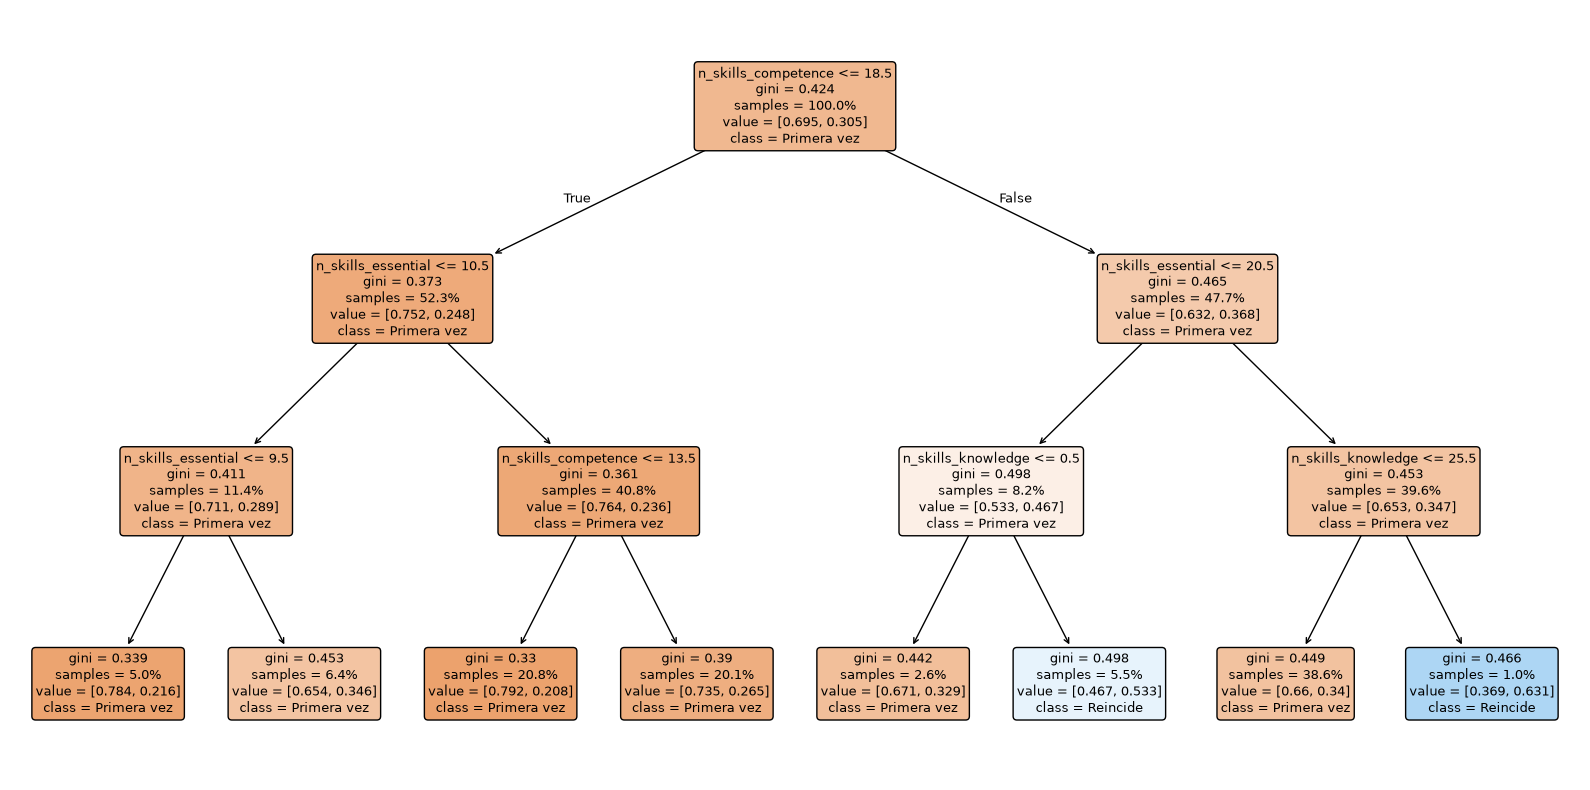

In [7]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(X_train, y_train)
print("train:", round(arbol.score(X_train, y_train), 4), "| test:", round(arbol.score(X_test, y_test), 4))

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(
    arbol,
    feature_names=list(X.columns),
    class_names=["Primera vez", "Reincide"],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9,
    ax=ax,
)
fig.tight_layout()
fig.savefig(FIGURAS / "arbol_skills.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
pred = arbol.predict(X_test)
print(classification_report(y_test, pred, target_names=["Primera vez", "Reincide"], zero_division=0))

              precision    recall  f1-score   support

 Primera vez       0.71      0.96      0.82     60503
    Reincide       0.55      0.12      0.20     26563

    accuracy                           0.70     87066
   macro avg       0.63      0.54      0.51     87066
weighted avg       0.66      0.70      0.63     87066



## 7 · Reglas en texto (`export_text`)

In [9]:
reglas = export_text(arbol, feature_names=list(X.columns), decimals=2)
print(reglas)
(REGLAS / "skills_export.txt").write_text(reglas, encoding="utf-8")

|--- n_skills_competence <= 18.50
|   |--- n_skills_essential <= 10.50
|   |   |--- n_skills_essential <= 9.50
|   |   |   |--- class: 0
|   |   |--- n_skills_essential >  9.50
|   |   |   |--- class: 0
|   |--- n_skills_essential >  10.50
|   |   |--- n_skills_competence <= 13.50
|   |   |   |--- class: 0
|   |   |--- n_skills_competence >  13.50
|   |   |   |--- class: 0
|--- n_skills_competence >  18.50
|   |--- n_skills_essential <= 20.50
|   |   |--- n_skills_knowledge <= 0.50
|   |   |   |--- class: 0
|   |   |--- n_skills_knowledge >  0.50
|   |   |   |--- class: 1
|   |--- n_skills_essential >  20.50
|   |   |--- n_skills_knowledge <= 25.50
|   |   |   |--- class: 0
|   |   |--- n_skills_knowledge >  25.50
|   |   |   |--- class: 1



750

## 8 · Cada hoja, con su tamaño y su tasa de reincidencia

In [10]:
t = arbol.tree_
hojas = np.where(t.children_left == -1)[0]
base = y_train.mean()

detalle = []
for h in hojas:
    valor = t.value[h, 0]          # proporción de cada clase en la hoja
    tasa = valor[1]
    n = t.n_node_samples[h]
    detalle.append({
        "hoja": int(h),
        "n_train": int(n),
        "reincide_%": round(100 * tasa, 1),
        "vs_base_pp": round(100 * (tasa - base), 1),
        "lift": round(tasa / base, 2),
        "predice": "Reincide" if valor.argmax() == 1 else "Primera vez",
    })

tabla_hojas = pd.DataFrame(detalle).sort_values("reincide_%", ascending=False)
tabla_hojas.to_csv(TABLAS / "skills_hojas.csv", index=False)
tabla_hojas

,hoja,n_train,reincide_%,vs_base_pp,lift,predice
7,14,2520,63.1,32.6,2.07,Reincide
5,11,14424,53.3,22.8,1.75,Reincide
1,4,16708,34.6,4.1,1.14,Primera vez
6,13,100846,34.0,3.5,1.12,Primera vez
4,10,6906,32.9,2.4,1.08,Primera vez
3,7,52430,26.5,-4.0,0.87,Primera vez
0,3,13103,21.6,-8.9,0.71,Primera vez
2,6,54260,20.8,-9.7,0.68,Primera vez


Solo **2 de las 8 hojas** predicen "reincide". Las otras seis son la clase mayoritaria. Eso ya es una conclusión: el fenómeno está concentrado.

## 9 · Las 2 reglas de negocio

Con los umbrales exactos que salen del `export_text` (tasa base = **30,5%**):

### Regla 1 · Oficios de perfil práctico con algo de teoría

> **"Oficios que exigen más de 18,5 competencias de tipo *competencia*, hasta 20,5 competencias esenciales en total y al menos un saber teórico: el 53,3% de los registros de personas en esos oficios son una repetición."**

`competence > 18.5` **Y** `essential <= 20.5` **Y** `knowledge > 0.5`
→ 14.424 registros (train) · **53,3%** reincide · **+22,8 pp** sobre la base · lift **1,75**

### Regla 2 · Oficios altamente especializados

> **"Oficios que exigen más de 18,5 competencias, más de 20,5 competencias esenciales y más de 25 saberes teóricos: el 63,1% de los registros son una repetición."**

`competence > 18.5` **Y** `essential > 20.5` **Y** `knowledge > 25.5`
→ 2.520 registros (train) · **63,1%** reincide · **+32,6 pp** sobre la base · lift **2,07**

**Traducción a acción (a quién se le asigna qué):**

| Regla | A quién se le asigna | Qué se le asigna | Por qué |
|---|---|---|---|
| **1** | Oficios de perfil práctico con algo de teoría (14.424 registros) | **Certificación de saberes previos + ruta de ascenso** | 53,3% ya repitió: la permanencia es estructural, conviene certificar lo que la persona ya sabe en vez de captarla de nuevo |
| **2** | Oficios altamente especializados (2.520 registros) | **Mesa técnica educación–trabajo + convenios de formación avanzada** | 63,1% repite: el cuello de botella está en la trayectoria, no en la atracción |

No se trata de "estudiar más" esos oficios: se trata de **asignarles el instrumento que corresponde a su tipo de perfil**. Y no se mira el total de 348.263 registros por igual: se empieza por los **16.944** donde repetir es la norma, no la excepción.

*(En la lógica de TelecomUNO: es la lista de llamadas priorizada. Aquí es la lista de oficios a los que se les asigna un programa, no una encuesta.)*


## 10 · Contraste: el mismo ejercicio con los otros dos bloques

Para que la elección de `X` no sea arbitraria, se repite el árbol con los otros dos bloques de variables, **a la misma profundidad (`max_depth=3`) y con el mismo split**:

- **ISCO**: los 9 grandes grupos ocupacionales.
- **Nivel educativo**: `nivel_ordinal` (1 = Secundaria … 4 = PhD) + bandera de "no reportado".
- **Competencias**: el árbol de la sección 6.

La única diferencia entre los tres es el conjunto de predictores.

In [11]:
def contar_hojas_reincide(arbol):
    """Cuenta las hojas cuya clase mayoritaria es 'reincide'."""
    t = arbol.tree_
    hojas = np.where(t.children_left == -1)[0]
    return sum(1 for h in hojas if t.value[h, 0].argmax() == 1), len(hojas)


def entrenar_bloque(X_bloque, nombre):
    """Mismo split, misma semilla y misma profundidad para cualquier bloque."""
    Xtr, Xte, ytr, yte = train_test_split(
        X_bloque, y, test_size=0.25, random_state=SEMILLA, stratify=y
    )
    modelo = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(Xtr, ytr)
    reincide, total = contar_hojas_reincide(modelo)
    print(f"--- {nombre} ---")
    print(export_text(modelo, feature_names=list(X_bloque.columns), decimals=2))
    return {
        "bloque": nombre,
        "acc_test": round(modelo.score(Xte, yte), 4),
        "hojas": total,
        "hojas_reincide": reincide,
    }


isco = pd.get_dummies(
    df["isco_group"].astype("string").str.slice(0, 1), prefix="isco", dtype=int
)
nivel = pd.DataFrame(
    {
        "nivel_ordinal": categorias.nivel_ordinal(df).astype("float64"),
        "nivel_no_reportado": categorias.nivel_no_reportado(df).astype(int),
    }
)

filas = [
    {
        "bloque": "baseline (most_frequent)",
        "acc_test": round(accuracy_score(y_test, pred_base), 4),
        "hojas": 1,
        "hojas_reincide": 0,
    },
    entrenar_bloque(isco, "isco_group"),
    entrenar_bloque(nivel, "nivel educativo"),
    {
        "bloque": "skills (competencias)",
        "acc_test": round(arbol.score(X_test, y_test), 4),
        "hojas": len(tabla_hojas),
        "hojas_reincide": int((tabla_hojas["predice"] == "Reincide").sum()),
    },
]

comparacion = pd.DataFrame(filas)
comparacion

--- isco_group ---
|--- isco_5 <= 0.50
|   |--- isco_3 <= 0.50
|   |   |--- isco_9 <= 0.50
|   |   |   |--- class: 0
|   |   |--- isco_9 >  0.50
|   |   |   |--- class: 0
|   |--- isco_3 >  0.50
|   |   |--- class: 0
|--- isco_5 >  0.50
|   |--- class: 0

--- nivel educativo ---
|--- nivel_ordinal <= 2.50
|   |--- nivel_ordinal <= 1.50
|   |   |--- class: 0
|   |--- nivel_ordinal >  1.50
|   |   |--- nivel_no_reportado <= 0.50
|   |   |   |--- class: 0
|   |   |--- nivel_no_reportado >  0.50
|   |   |   |--- class: 0
|--- nivel_ordinal >  2.50
|   |--- nivel_ordinal <= 3.50
|   |   |--- class: 0
|   |--- nivel_ordinal >  3.50
|   |   |--- class: 0



,bloque,acc_test,hojas,hojas_reincide
0,baseline (most_frequent),0.6949,1,0
1,isco_group,0.6949,4,0
2,nivel educativo,0.6949,5,0
3,skills (competencias),0.7015,8,2


**Resultado del contraste** (mismo split, `max_depth=3`):

| Bloque | accuracy test | hojas | hojas que predicen "reincide" |
|---|---|---|---|
| baseline | 0,6949 | 1 | 0 |
| ISCO | 0,6949 | 4 | **0** |
| nivel educativo | 0,6949 | 5 | **0** |
| competencias | **0,7015** | 8 | **2** |

Los bloques ISCO y nivel educativo **no producen ninguna hoja que prediga "reincide"**: toda su segmentación se queda por debajo del 50%, así que no permiten escribir una sola regla accionable. El bloque de competencias sí.

Eso no significa que "las competencias causen la reincidencia". Significa que el **perfil de competencias del oficio separa mejor** que el gran grupo ISCO y que el nivel educativo, y esa es la comparación que el ejercicio permite sostener.

## 11 · Limitaciones (lo que este modelo NO dice)

1. **No es causal.** "Los oficios con muchas competencias se repiten más" es una asociación, no una causa.
2. **Las competencias son del oficio, no de la persona.** Todos los meseros comparten el mismo `n_skills_essential`. El modelo clasifica **oficios**, no personas: la pregunta real es *"¿qué tipo de oficio se repite?"*, no *"¿qué persona va a repetir?"*.
3. **Hay circularidad parcial.** Las competencias se pegan al `occupation_code`, y la etiqueta se construye repitiendo `occupation_code`. El modelo describe el oficio desde otro ángulo; no descubre un factor nuevo.
4. **Accuracy engañosa.** Con 30,5% de positivos, 70% de accuracy se puede conseguir sin identificar a nadie (el baseline lo demuestra). Por eso se reportan `f1`, `recall` y el lift de las hojas.
5. **Confusor probable.** Los oficios con más competencias en ESCO suelen ser oficios amplios y comunes, con alta entrada y salida de personas. La rotación podría explicarse por el tamaño del oficio, no por las competencias.

## 12 · Conclusión

- El árbol **no se sobreajusta** (train ≈ test en todas las profundidades): el límite está en el dato, no en el modelo.
- Se elige `max_depth=3` por **legibilidad**, no por accuracy.
- El bloque de competencias separa la reincidencia mejor que el grupo ISCO: **70,1% vs 69,5%**, y sobre todo **produce 2 hojas con mayoría de "reincide"**, que es lo que permite escribir reglas.
- Las 2 reglas concentran el hallazgo: oficios de perfil práctico-con-teórico (**53,3%**) y oficios altamente especializados (**63,1%**) repiten muy por encima del 30,5% general.
- **Para el proyecto:** esto es un lente descriptivo sobre oficios. La pregunta de investigación (transiciones y permanencias por persona) se responde con secuencias y matrices de transición, no con este árbol.